# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** Устройство: Kaggle, Tesla T4 16 ГБ; ultralytics 8.4.216, torch 2.11.0+cu130. Модель: `yolo26s.pt`. Датасет: Thermal Person Detector, https://huggingface.co/datasets/Voxel51/Thermal-Person-Detector (исходно Roboflow smart2/persondection-61bc2), лицензия CC BY 4.0. Бонусы: 6.2, 6.3, 6.4, 6.5. Не решено: 6.1.

Весь ноутбук с `FAST_MODE = False` считался 3.4 часа. Обучение заняло 30.5 мин, абляция 13 мин, RT-DETR из 6.2 почти 2 часа, остальное ушло на валидации и сборку TensorRT.

In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.216, torch 2.11.0+cu130, device: Tesla T4


In [2]:
FAST_MODE = False  # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 30
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26s.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)


def count_params(module):
    return sum(p.numel() for p in module.parameters())


def measure_latency(model, imgsz=IMGSZ, n_runs=50, **kw):
    # мс на картинку: model.predict целиком (препроцессинг, сеть, постпроцессинг), после 10 прогревочных запусков
    image = np.random.default_rng(SEED).integers(0, 256, (imgsz, imgsz, 3), dtype=np.uint8)
    times = []
    for i in range(10 + n_runs):
        torch.cuda.synchronize()
        start = time.perf_counter()
        model.predict(image, imgsz=imgsz, device=DEVICE, verbose=False, **kw)
        torch.cuda.synchronize()
        times.append(time.perf_counter() - start)
    return 1000 * float(np.mean(times[10:]))


MODEL_INFO = dict(
    ultralytics=ultralytics.__version__,
    weights=weights_path.name,
    sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
    size_mb=round(weights_path.stat().st_size / 2**20, 2),
    params=count_params(model_coco.model),   # до первого predict, пока Conv и BN не слиты
    n_classes_coco=len(model_coco.names),
    latency_ms=measure_latency(model_coco),
)

In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26s.pt',
 'sha256': '646f8bc3fe0a656803d95c294f7852321748cb29d13466a1af8862e2db384a1b',
 'size_mb': 19.48,
 'params': 10009784,
 'n_classes_coco': 80,
 'latency_ms': 14.119006260000333}

**Ответ:** Взял `yolo26s`: 10.0 млн параметров (9.5 млн после слияния Conv и BN), 48.6 mAP50-95 на COCO. У `yolo26n` 2.4 млн и 40.9, у `yolo26m` 20.4 млн и 53.1. В таблице документации на T4 с TensorRT это 1.7, 2.5 и 4.7 мс; у меня в PyTorch FP32 на одной картинке 640 вышло 14.1 мс.

Люди на тепловизоре мелкие и размытые, и терять 7.7 пункта COCO mAP на n не хотелось. m по FLOPs в 3.3 раза дороже s (68.4 против 20.9 GFLOPs), а s на T4 и так учится 61 с на эпоху на 3000 картинках. m учился бы примерно втрое дольше, и вместе с абляцией бюджет в час был бы превышен.

Код и веса ultralytics выпущены под AGPL-3.0 (или под платную Enterprise-лицензию). AGPL требует открыть исходники всей программы под той же лицензией, если ее распространять или давать к ней доступ по сети.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    return dict(backbone=count_params(layers[:n_backbone]),
                neck=count_params(layers[n_backbone:-1]),
                head=count_params(layers[-1]))


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    feats = []
    hook = det_model.model[-1].register_forward_pre_hook(lambda m, args: feats.extend(tuple(x.shape) for x in args[0]))
    det_model.eval()
    with torch.no_grad():
        out = det_model(torch.zeros(1, 3, imgsz, imgsz))
    hook.remove()
    return feats, out


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '5,441,984 (54%)', 'neck': '3,574,016 (36%)', 'head': '993,784 (10%)'} total 10,009,784
на входе Detect: [(1, 128, 80, 80), (1, 256, 40, 40), (1, 512, 20, 20)]


In [8]:
print('выход:', shapes(out))
print('end2end:', arch.model[-1].end2end)

layer_out = {}
hooks = [m.register_forward_hook(lambda m, inp, o, i=i: layer_out.update({i: shapes(o)})) for i, m in enumerate(arch.model[:-1])]
with torch.no_grad():
    arch(torch.zeros(1, 3, 640, 640))
for h in hooks:
    h.remove()

n_backbone = len(arch.yaml['backbone'])
for i, m in enumerate(arch.model):
    block = 'backbone' if i < n_backbone else 'neck' if i < len(arch.model) - 1 else 'head'
    print(f'{i:>2} {block:<8} {type(m).__name__:<9} from={str(m.f):<12} {count_params(m):>9,}  {layer_out.get(i, "")}')

выход: [(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 128, 80, 80), (1, 256, 40, 40), (1, 512, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 128, 80, 80), (1, 256, 40, 40), (1, 512, 20, 20)]}}]
end2end: False
 0 backbone Conv      from=-1                 928  (1, 32, 320, 320)
 1 backbone Conv      from=-1              18,560  (1, 64, 160, 160)
 2 backbone C3k2      from=-1              26,080  (1, 128, 160, 160)
 3 backbone Conv      from=-1             147,712  (1, 128, 80, 80)
 4 backbone C3k2      from=-1             103,360  (1, 256, 80, 80)
 5 backbone Conv      from=-1             590,336  (1, 256, 40, 40)
 6 backbone C3k2      from=-1             346,112  (1, 256, 40, 40)
 7 backbone Conv      from=-1           1,180,672  (1, 512, 20, 20)
 8 backbone C3k2      from=-1           1,380,352  (1, 512, 20, 20)
 9 backbone SPPF      from=-1             656,896  (1, 512, 20, 20)
10 backbone C2PSA     f

**Ответ:** Backbone (слои 0-10, 5.44 млн, 54% параметров) свертками со stride 2 сжимает картинку до карт со stride 8, 16 и 32 и считает признаки. В конце SPPF собирает контекст с разных рецептивных полей, а C2PSA добавляет attention. Neck (слои 11-22, 3.57 млн, 36%) устроен как FPN+PAN. Сначала он идет сверху вниз (upsample и concat с выходами слоев 6 и 4), потом снизу вверх (свертки со stride 2). На выходе получаются три карты: 128×80×80, 256×40×40 и 512×20×20, для мелких, средних и крупных объектов.

Head `Detect` (0.99 млн, 10%) в каждой точке каждой карты предсказывает 4 расстояния от центра ячейки до сторон бокса и 80 оценок классов. Заранее заданных якорных боксов нет, поэтому детектор anchor-free. Всего точек 80² + 40² + 20² = 6400 + 1600 + 400 = 8400.

Ветка `one2many` при обучении получает несколько положительных точек на объект. Сигнал от этого сильнее, но на выходе остаются дубли, и их убирает NMS. Ветка `one2one` учится с назначением один к одному, сама не выдает дублей, и NMS ей не нужен.

В ultralytics 8.4.216 загруженная модель печатает `end2end: False`, и `predict`/`val` по умолчанию идут через `one2many` + NMS. Режим без NMS включается флагом `nms=False`, сравнение в 6.5.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
import re
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

REPO = 'Voxel51/Thermal-Person-Detector'
DATASET_NAME = ('Thermal Person Detector, https://huggingface.co/datasets/Voxel51/Thermal-Person-Detector '
                '(исходно Roboflow smart2/persondection-61bc2), CC BY 4.0')
CLASSES = ['person']
N_TRAIN = 3000   # из 6145 картинок train: весь train с RT-DETR и абляцией не укладывается в разумное время на T4

# разметка (FiftyOne samples.json) и картинки (parquet-конвертация HF) с зафиксированных коммитов
raw_dir, image_dir = DATA_ROOT / 'raw', DATA_ROOT / 'images'
samples_path = hf_hub_download(REPO, 'samples.json', repo_type='dataset', local_dir=raw_dir,
                               revision='aba2adf43d163611da6af20115e564b40a90f917')
parquet_path = hf_hub_download(REPO, 'default/train/0000.parquet', repo_type='dataset', local_dir=raw_dir,
                               revision='60978dfed1320ca835cbadeae102e3b168c03653')
image_dir.mkdir(parents=True, exist_ok=True)
images = pq.read_table(parquet_path).column('image').combine_chunks()
for name, data in zip(images.field('path').to_pylist(), images.field('bytes').to_pylist()):
    (image_dir / name).write_bytes(data)

all_recs, n_clipped, n_dropped = [], 0, 0
for s in json.loads(Path(samples_path).read_text())['samples']:
    path = image_dir / Path(s['filepath']).name
    w, h = Image.open(path).size
    dets = s['ground_truth']['detections']
    xywh = np.array([d['bounding_box'] for d in dets]).reshape(-1, 4) * [w, h, w, h]   # x, y левого верхнего угла, доли
    boxes = np.concatenate([xywh[:, :2], xywh[:, :2] + xywh[:, 2:]], 1)
    clipped = np.clip(boxes, 0, [w, h, w, h])
    keep = (clipped[:, 2] - clipped[:, 0] >= 1) & (clipped[:, 3] - clipped[:, 1] >= 1)
    n_clipped += int((np.abs(clipped - boxes) > 1e-6).any(1).sum())
    n_dropped += int((~keep).sum())
    all_recs.append(dict(image=path, width=w, height=h, boxes=clipped[keep].astype(np.float32),
                         labels=np.zeros(keep.sum(), dtype=np.int64), source_split=s['tags'][0]))
print(f'картинок {len(all_recs)}, боксов обрезано {n_clipped}, выкинуто {n_dropped}')


def dhash(path):
    a = np.asarray(Image.open(path).convert('L').resize((17, 16)), dtype=np.float32)
    return (a[:, 1:] > a[:, :-1]).ravel().astype(np.float32)


# В одном сплите должны оказаться кадры одного видео и почти одинаковые картинки (dHash отличается <= 8 бит из 256).
# Иначе модель видит на test соседние кадры из train
hashes = np.stack([dhash(r['image']) for r in all_recs])
pairs = []
for s in range(0, len(hashes), 2048):
    dist = hashes.shape[1] - hashes[s:s + 2048] @ hashes.T - (1 - hashes[s:s + 2048]) @ (1 - hashes).T
    i, j = np.nonzero(dist <= 8)
    pairs += [(a + s, b) for a, b in zip(i, j) if b > a + s]
videos = [m.group(1) if (m := re.match(r'video-(\w+?)-frame', r['image'].name)) else None for r in all_recs]
first = {}
pairs += [(first.setdefault(v, k), k) for k, v in enumerate(videos) if v]
pairs = np.array(pairs)
n_groups, group = connected_components(coo_matrix((np.ones(len(pairs)), pairs.T), shape=(len(all_recs),) * 2))

src = {}
for g, r in zip(group, all_recs):
    src.setdefault(g, set()).add(r['source_split'])
leaky = {g for g, s in src.items() if len(s) > 1}
print(f'видео {len(first)}, групп {n_groups}; в исходном разбиении {len(leaky)} групп '
      f'({sum(g in leaky for g in group)} картинок) лежат сразу в нескольких сплитах')

# новый сплит 70 / 15 / 15 по группам
order = np.random.default_rng(SEED).permutation(n_groups)
cum = np.cumsum(np.bincount(group)[order]) / len(all_recs)
split_of = dict(zip(order, np.where(cum <= 0.7, 'train', np.where(cum <= 0.85, 'val', 'test'))))
records = {'train': [], 'val': [], 'test': []}
for g, r in zip(group, all_recs):
    records[split_of[g]].append({k: v for k, v in r.items() if k != 'source_split'})
n_train_all = len(records['train'])
records['train'] = [records['train'][i] for i in sorted(np.random.default_rng(SEED).permutation(n_train_all)[:N_TRAIN])]
print(f'train {n_train_all} -> {N_TRAIN} (случайное подмножество)')

samples.json:   0%|          | 0.00/6.14M [00:00<?, ?B/s]

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  266MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

картинок 8778, боксов обрезано 0, выкинуто 0
видео 110, групп 7308; в исходном разбиении 15 групп (358 картинок) лежат сразу в нескольких сплитах
train 6144 -> 3000 (случайное подмножество)


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 3000, 'val': 1317, 'test': 1317}

train картинок  3000, людей  6342, пустых 229, на картинку 2.11 (max 18)
val   картинок  1317, людей  2802, пустых 114, на картинку 2.13 (max 11)
test  картинок  1317, людей  2904, пустых  88, на картинку 2.21 (max 10)
боксы: small (< 32 px) 11.9%, medium 34.4%, large (>= 96 px) 53.7%; на всю высоту картинки 4.1%


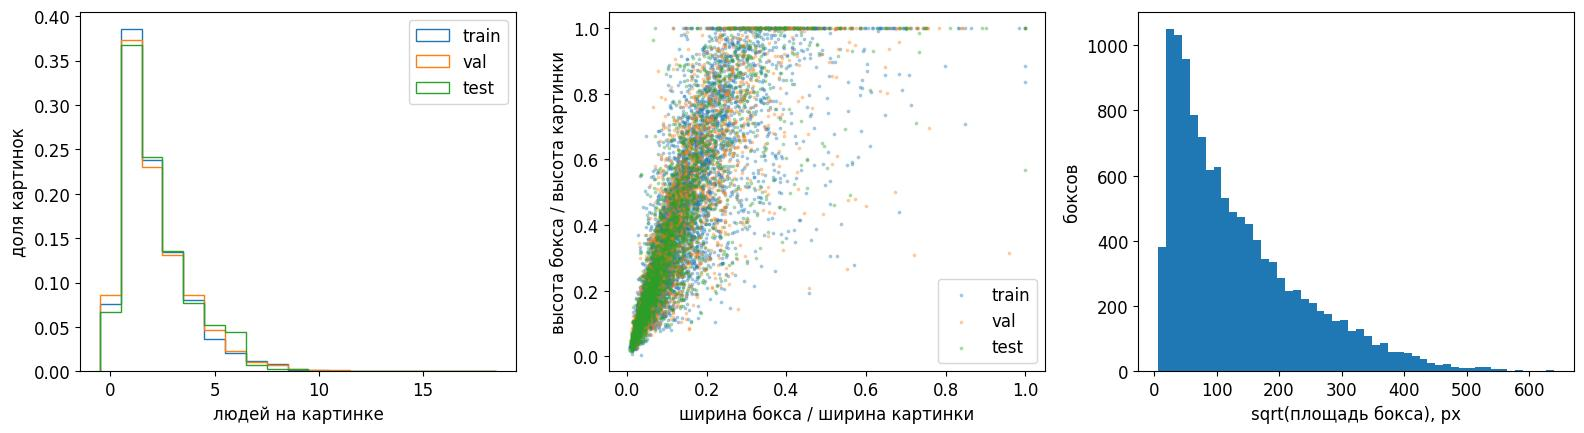

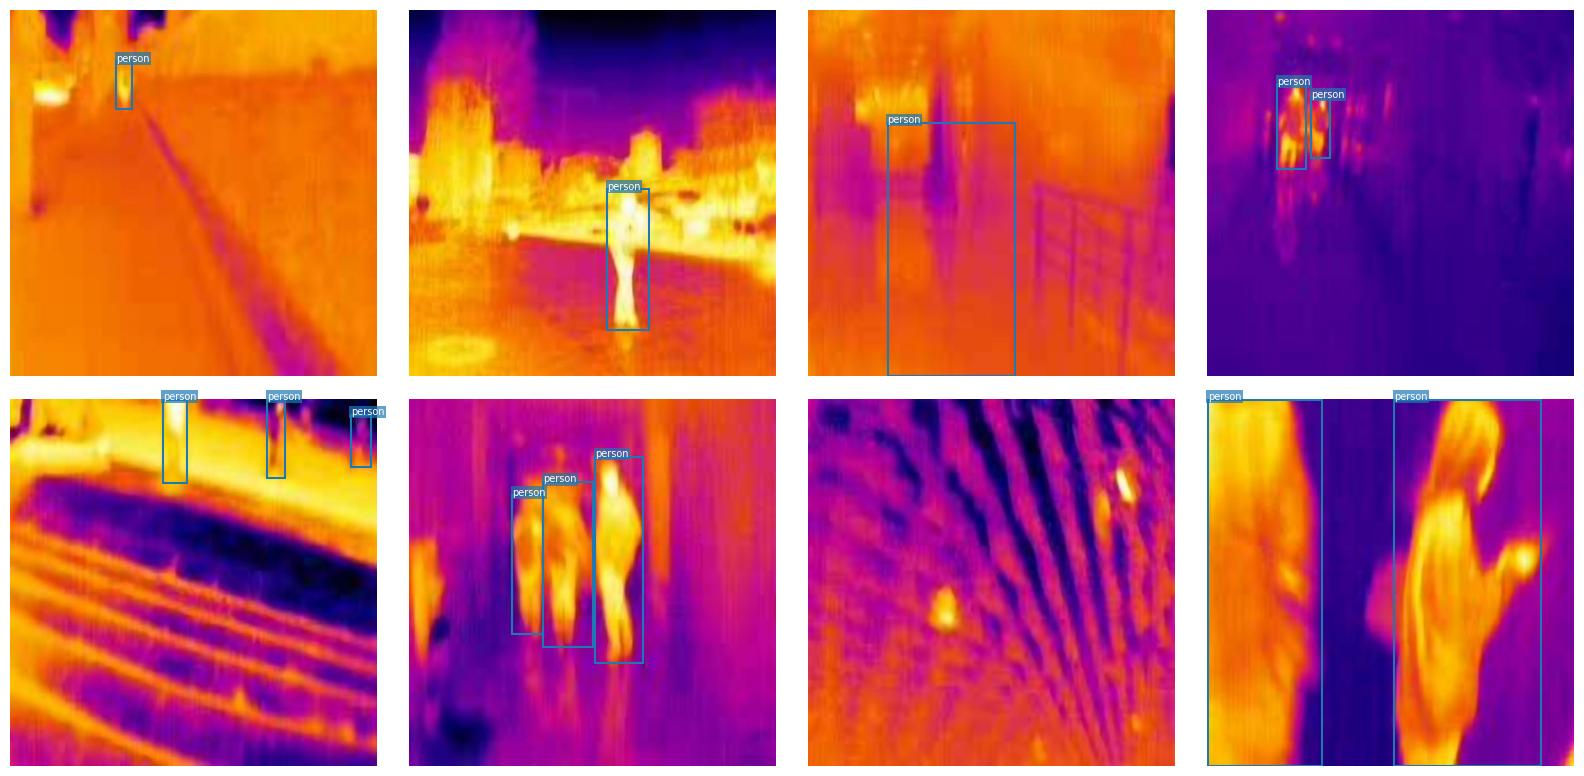

In [11]:
for split, recs in records.items():
    n = np.array([len(r['labels']) for r in recs])
    print(f'{split:<5} картинок {len(recs):>5}, людей {n.sum():>5}, пустых {(n == 0).sum():>3}, '
          f'на картинку {n.mean():.2f} (max {n.max()})')

wh = {s: np.concatenate([(r['boxes'][:, 2:] - r['boxes'][:, :2]) / [r['width'], r['height']] for r in recs])
      for s, recs in records.items()}
side = np.sqrt(np.concatenate([np.prod(r['boxes'][:, 2:] - r['boxes'][:, :2], 1) for recs in records.values() for r in recs]))
print(f'боксы: small (< 32 px) {np.mean(side < 32):.1%}, medium {np.mean((side >= 32) & (side < 96)):.1%}, '
      f'large (>= 96 px) {np.mean(side >= 96):.1%}; на всю высоту картинки {np.mean(np.concatenate(list(wh.values()))[:, 1] > 0.99):.1%}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for split, recs in records.items():
    axes[0].hist([len(r['labels']) for r in recs], bins=np.arange(20) - 0.5, histtype='step', density=True, label=split)
    axes[1].scatter(wh[split][:, 0], wh[split][:, 1], s=3, alpha=0.3, label=split)
axes[2].hist(side, bins=50)
axes[0].set(xlabel='людей на картинке', ylabel='доля картинок')
axes[1].set(xlabel='ширина бокса / ширина картинки', ylabel='высота бокса / высота картинки')
axes[2].set(xlabel='sqrt(площадь бокса), px', ylabel='боксов')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.flat, np.random.default_rng(SEED).choice(len(records['train']), 8, replace=False)):
    r = records['train'][i]
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES)
plt.tight_layout()
plt.show()

**Ответ:** Thermal Person Detector с Hugging Face (Voxel51, исходно Roboflow smart2/persondection-61bc2), CC BY 4.0. Это 8778 тепловизионных кадров 640×640 в цветной палитре (ironbow) и в оттенках серого, класс один (person), всего 18695 боксов.

Исходное разбиение протекает. Кадры из 110 видео и почти одинаковые картинки (dHash, расхождение до 8 бит) лежат в разных сплитах: 15 таких групп, 358 картинок. Я собрал кадры в 7308 групп и разбил по группам 70/15/15 с seed 0. Из 6144 картинок train ради бюджета T4 взял случайные 3000, в val и test по 1317.

Дисбаланса классов при одном классе нет, сцены не плотные: 2.1 человека на картинку, максимум 18. Мелких боксов (< 32 px) 11.9%, крупных (≥ 96 px) 53.7%. Обрезанных и нулевых боксов не нашлось, но 4.1% боксов занимают всю высоту кадра. В 5.1 видны вложенные боксы (голова отдельным боксом внутри человека) и неразмеченные люди.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    b = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    cx, cy = (b[:, 0] + b[:, 2]) / 2 / width, (b[:, 1] + b[:, 3]) / 2 / height
    w, h = (b[:, 2] - b[:, 0]) / width, (b[:, 3] - b[:, 1]) / height
    return ''.join(f'{c} {x:.6f} {y:.6f} {bw:.6f} {bh:.6f}\n'
                   for c, x, y, bw, bh in zip(np.asarray(labels, dtype=int).reshape(-1), cx, cy, w, h))


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    a = np.array([line.split() for line in text.splitlines() if line.strip()], dtype=np.float64).reshape(-1, 5)
    cx, cy, w, h = a[:, 1] * width, a[:, 2] * height, a[:, 3] * width, a[:, 4] * height
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1)
    return boxes.astype(np.float32), a[:, 0].astype(np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    (YOLO_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
    (YOLO_ROOT / 'labels' / split).mkdir(parents=True, exist_ok=True)
    for i, r in enumerate(recs):
        name = f'{i:05d}_{r["image"].stem}'   # номер спереди: имена уникальны и сортируются в порядке recs
        shutil.copy(r['image'], YOLO_ROOT / 'images' / split / f'{name}.jpg')
        (YOLO_ROOT / 'labels' / split / f'{name}.txt').write_text(to_yolo(r['boxes'], r['labels'], r['width'], r['height']))


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /kaggle/working/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: person



туда-обратно по всем сплитам: максимальное расхождение 0.0005 px


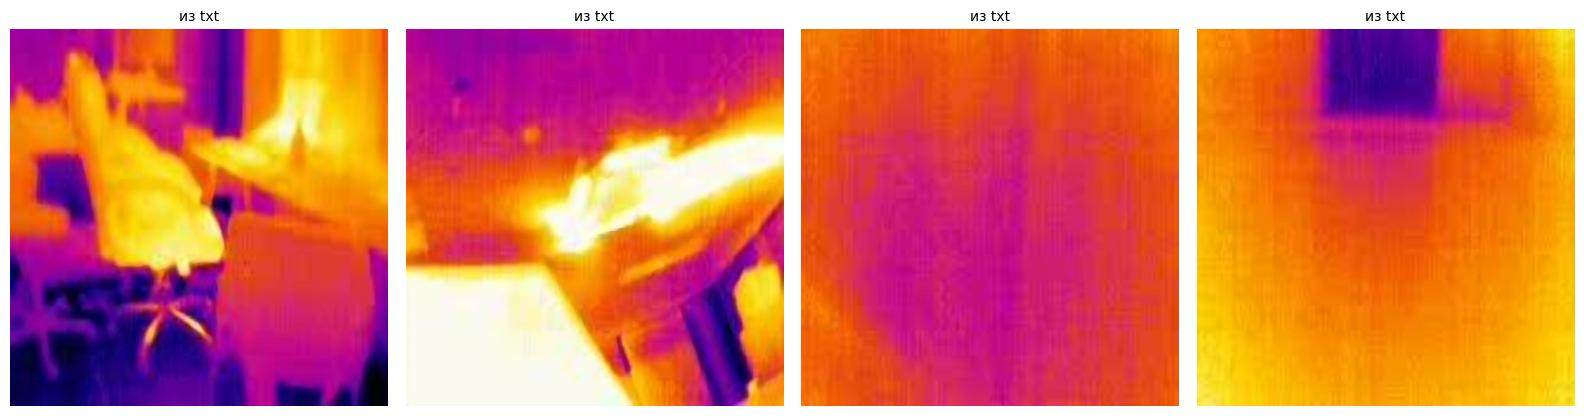

In [15]:
max_err = 0
for split, recs in splits.items():
    for r, f in zip(recs, sorted((YOLO_ROOT / 'labels' / split).glob('*.txt'))):
        b, l = from_yolo(f.read_text(), r['width'], r['height'])
        assert f.stem.endswith(r['image'].stem) and (l == r['labels']).all() and b.shape == r['boxes'].shape, f
        max_err = max(max_err, np.abs(b - r['boxes']).max(initial=0))
print(f'туда-обратно по всем сплитам: максимальное расхождение {max_err:.4f} px')

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, img in zip(axes, sorted((YOLO_ROOT / 'images' / 'train').glob('*.jpg'))[:4]):
    image = Image.open(img)
    b, l = from_yolo((YOLO_ROOT / 'labels' / 'train' / f'{img.stem}.txt').read_text(), *image.size)
    draw_boxes(ax, image, b, l, CLASSES, title='из txt')
plt.tight_layout()
plt.show()

**Ответ:** Тест туда-обратно проверяет, что `to_yolo` и `from_yolo` взаимно обратны: по всем сплитам максимальное расхождение 0.0005 px, это округление до 6 знаков. Ошибку, сделанную одинаково в обеих функциях, он не ловит. Если перепутать x и y или ширину с высотой и там, и там, числа вернутся те же, а боксы окажутся не на людях. Не ловит он и txt, лишь записанный рядом с чужой картинкой: в этом датасете одинаковое имя файла бывает у разных картинок, поэтому файлы называются `{индекс}_{имя}`. Перепутанные оси, неверный размер картинки и сдвиг на полбокса (центр против угла) видно только при отрисовке боксов, прочитанных из txt.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

COCO-модель на test: mAP50 = 0.532
что видит COCO-модель при conf >= 0.25: [('car', 1678), ('person', 1314), ('traffic light', 89), ('bicycle', 70), ('truck', 34), ('dog', 18)]


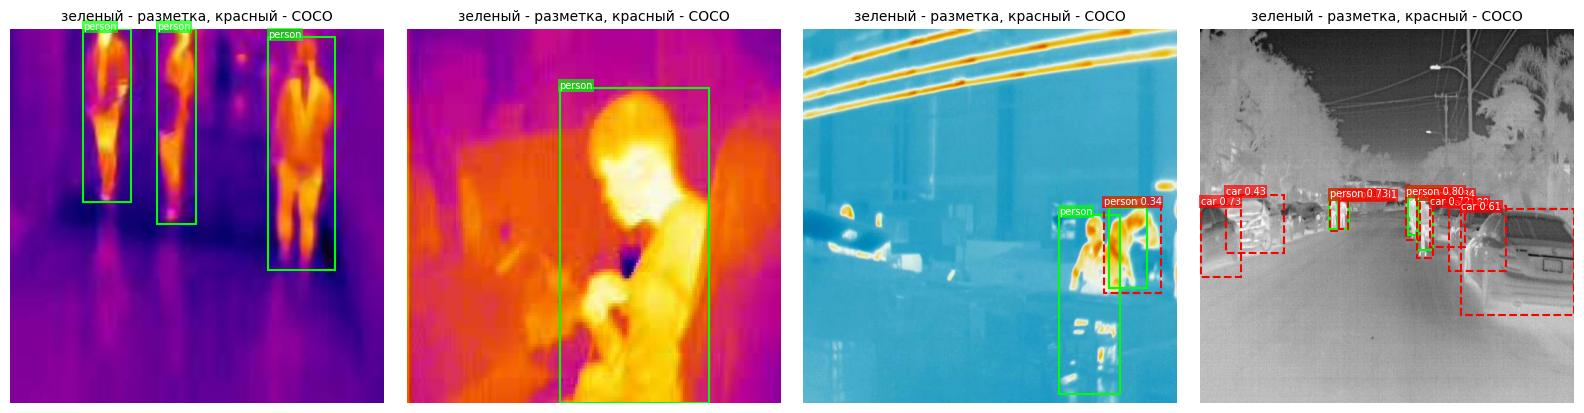

In [16]:
coco_raw = predict_records(model_coco, records[FINAL_SPLIT])
coco_preds = [dict(boxes=p['boxes'][p['labels'] == 0], scores=p['scores'][p['labels'] == 0],
                   labels=np.zeros((p['labels'] == 0).sum(), dtype=np.int64)) for p in coco_raw]   # COCO person -> наш person
coco_map50, _ = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'COCO-модель на {FINAL_SPLIT}: mAP50 = {coco_map50:.3f}')
print('что видит COCO-модель при conf >= 0.25:',
      Counter(model_coco.names[c] for p in coco_raw for c in p['labels'][p['scores'] >= 0.25]).most_common(6))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, k in zip(axes, np.random.default_rng(SEED).choice(len(records[FINAL_SPLIT]), 4, replace=False)):
    r, p = records[FINAL_SPLIT][k], coco_raw[k]
    keep = p['scores'] >= 0.25
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='lime')
    draw_boxes(ax, None, p['boxes'][keep], p['labels'][keep], model_coco.names, p['scores'][keep], color='red',
               linestyle='--', title='зеленый - разметка, красный - COCO')
plt.tight_layout()
plt.show()

In [17]:
def heuristic_on_array(rgb, percentile, min_aspect, min_area):
    # В палитре тепловизора теплое светлее. Самые яркие пиксели -> связные компоненты -> оставляем те,
    # что похожи на человека: не слишком маленькие и вытянутые по вертикали
    temp = rgb.astype(np.float32) @ [0.299, 0.587, 0.114]
    lab, _ = ndimage.label(ndimage.binary_opening(temp >= np.percentile(temp, percentile)))
    boxes, scores = [], []
    for k, (ys, xs) in enumerate(ndimage.find_objects(lab), start=1):
        w, h = xs.stop - xs.start, ys.stop - ys.start
        if w * h >= min_area * temp.size and h >= min_aspect * w:
            boxes.append([xs.start, ys.start, xs.stop, ys.stop])
            scores.append(temp[ys, xs][lab[ys, xs] == k].mean())
    return dict(boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4), scores=np.array(scores),
                labels=np.zeros(len(boxes), dtype=np.int64))


def load_small(path):
    return np.asarray(Image.open(path).convert('RGB').reduce(2))   # в 2 раза меньше: быстрее, на mAP50 не влияет


def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    pred = heuristic_on_array(load_small(image_path), **HEURISTIC_PARAMS)
    pred['boxes'] *= 2
    return pred

In [18]:
# ваш код: параметры эвристики, если нужны (подбирать по train, не по val)
import itertools

tune_recs = [records['train'][i] for i in np.random.default_rng(SEED).choice(len(records['train']), 300, replace=False)]
tune_images = [load_small(r['image']) for r in tune_recs]
tuning = []
for pct, aspect, area in itertools.product([90, 95, 98], [0.5, 1.0, 1.5], [0.0005, 0.003]):
    params = dict(percentile=pct, min_aspect=aspect, min_area=area)
    preds = [heuristic_on_array(a, **params) for a in tune_images]
    for p in preds:
        p['boxes'] *= 2
    tuning.append((evaluate_map50(preds, tune_recs, len(CLASSES))[0], params))
best_train_map50, HEURISTIC_PARAMS = max(tuning, key=lambda t: t[0])
print(f'лучшие параметры на 300 картинках train: {HEURISTIC_PARAMS}, mAP50 {best_train_map50:.3f}')

лучшие параметры на 300 картинках train: {'percentile': 90, 'min_aspect': 1.5, 'min_area': 0.003}, mAP50 0.029


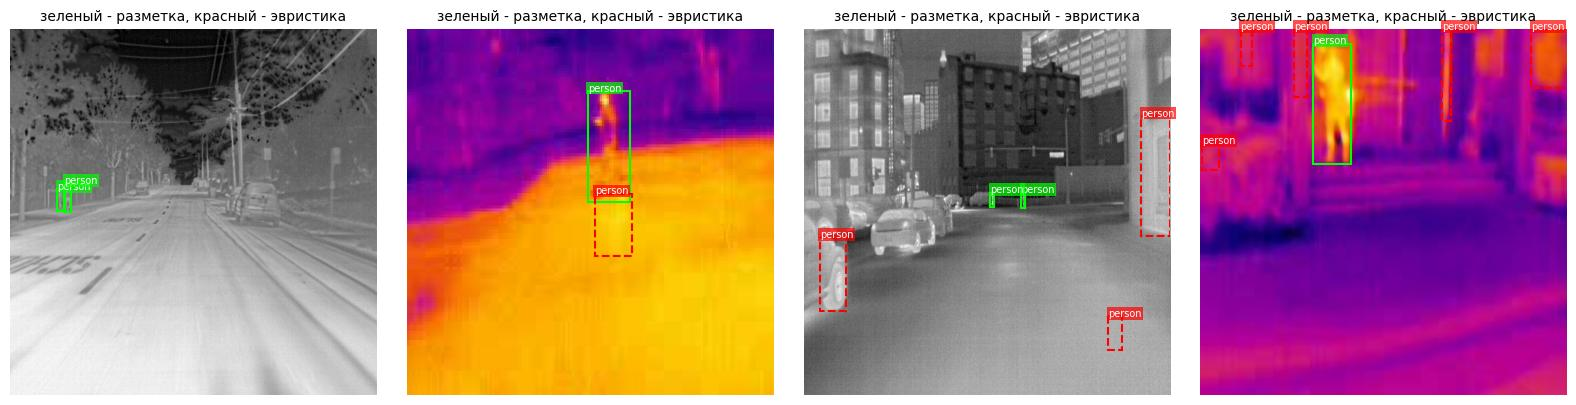

{'split': 'test',
 'coco_map50': 0.5324171506720643,
 'heuristic_map50': 0.03228048863485944,
 'heuristic_ap50_per_class': {'person': 0.03228048863485944}}

In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, k in zip(axes, np.random.default_rng(SEED + 1).choice(len(records[FINAL_SPLIT]), 4, replace=False)):
    r, p = records[FINAL_SPLIT][k], heuristic_preds[k]
    top = np.argsort(-p['scores'])[:5]
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='lime')
    draw_boxes(ax, None, p['boxes'][top], p['labels'][top], CLASSES, color='red', linestyle='--',
               title='зеленый - разметка, красный - эвристика')
plt.tight_layout()
plt.show()
BASELINE

**Ответ:** COCO-модель без дообучения дает на test mAP50 0.532 (класс person переназначен в 0). Тепловизионных кадров в COCO почти нет, а цвет в палитре означает температуру и не похож на одежду и кожу. При conf ≥ 0.25 модель чаще отвечает car (1678 боксов), чем person (1314). Форму человека она все же узнает, поэтому mAP не нулевой.

Эвристика ищет пятна ярче перцентиля по кадру, чистит их морфологией и делит на связные компоненты с фильтром по площади и вытянутости. Параметры подобраны на 300 картинках train (там mAP50 0.029), на test mAP50 0.032. Класс один, и проваливается она на нем: палитра растягивается под каждый кадр, поэтому самыми горячими часто оказываются стены, лампы и асфальт. Соседние люди сливаются в одну компоненту, а далекие не проходят порог площади.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(
    epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED, deterministic=True,
    optimizer='AdamW', lr0=1e-3, cos_lr=True, patience=10,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.3,   # цвет в палитре тепловизора - это температура, тон и насыщенность не трогаем
    fliplr=0.5, flipud=0.0,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30       5.6G      1.552      1.454    0.01522         22        640: 100% ━━━━━━━━━━━━ 188/188 4.0it/s 47.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 3.6it/s 11.7s
                   all       1317       2802      0.738      0.631      0.713      0.403

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/30       5.6G      1.525      1.384    0.01488         18        640: 100% ━━━━━━━━━━━━ 188/188 4.0it/s 47.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 3.6it/s 11.6s
                   all       1317       2802      0.751       0.66      0.746      0.427

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/30       5.6G      1.522      1.337    0.01455         31        640: 100% ━━━━━━━━━━━━ 188/188 3.9it/s 47.6s
                 Class     Images  Instances      B

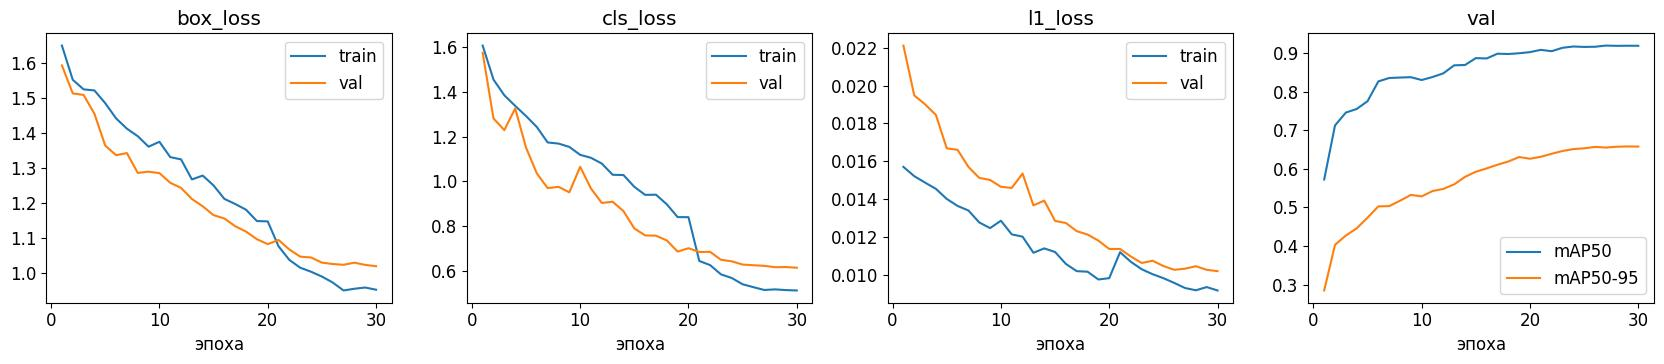

эпох: 30, лучшая по mAP50-95: 29, 61 s/эпоха, Tesla T4


In [22]:
res = read_results(run_dir)
losses = sorted(k[6:] for k in res if k.startswith('train/'))
fig, axes = plt.subplots(1, len(losses) + 1, figsize=(4.2 * (len(losses) + 1), 3.8))
for ax, name in zip(axes, losses):
    ax.plot(res['epoch'], res[f'train/{name}'], label='train')
    ax.plot(res['epoch'], res[f'val/{name}'], label='val')
    ax.set(title=name, xlabel='эпоха')
    ax.legend()
axes[-1].plot(res['epoch'], res['metrics/mAP50(B)'], label='mAP50')
axes[-1].plot(res['epoch'], res['metrics/mAP50-95(B)'], label='mAP50-95')
axes[-1].set(title='val', xlabel='эпоха')
axes[-1].legend()
plt.tight_layout()
plt.show()
print(f'эпох: {len(res["epoch"])}, лучшая по mAP50-95: {int(res["epoch"][res["metrics/mAP50-95(B)"].argmax()])}, '
      f'{RUN_TIMES["train"] / len(res["epoch"]):.0f} s/эпоха, {DEVICE_NAME}')

**Ответ:** 30 эпох по 61 с на T4 (30.5 мин) с `patience=10`. `imgsz=640`: 11.9% людей меньше 32 px, при 320 они стали бы меньше 16 px. `batch=16` помещается в память T4. Для короткого дообучения взял AdamW с lr0 1e-3 и косинусным расписанием.

Выключил `hsv_h` и `hsv_s`: в палитре цвет означает температуру, и сдвиг тона сделал бы холодный фон «горячим». `hsv_v=0.3` оставил под разную яркость камер. `fliplr=0.5` включен, `flipud=0`: люди в кадре стоят вертикально.

Переобучения нет. Val box loss упал с 1.59 до 1.02, val cls loss с 1.57 до 0.62, и оба почти монотонно снижались до последней эпохи. Резкое падение train loss после 20-й эпохи вызван отключением mosaic (`close_mosaic=10`). Лучшая эпоха 29 из 30, но mAP50-95 на val за последние 5 эпох вырос только с 0.653 до 0.658, так что новые эпохи дали бы немного.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1236.7±525.6 MB/s, size: 37.4 KB)
val: Scanning /kaggle/working/data/yolo/labels/val.cache... 1317 images, 114 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1317/1317 394.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 83/83 3.7it/s 22.7s
                   all       1317       2802      0.915      0.833      0.919      0.658
Speed: 0.9ms preprocess, 13.3ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /kaggle/working/runs_hw2/val_val
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 825.5±331.2 MB/s, size: 28.0 KB)
va

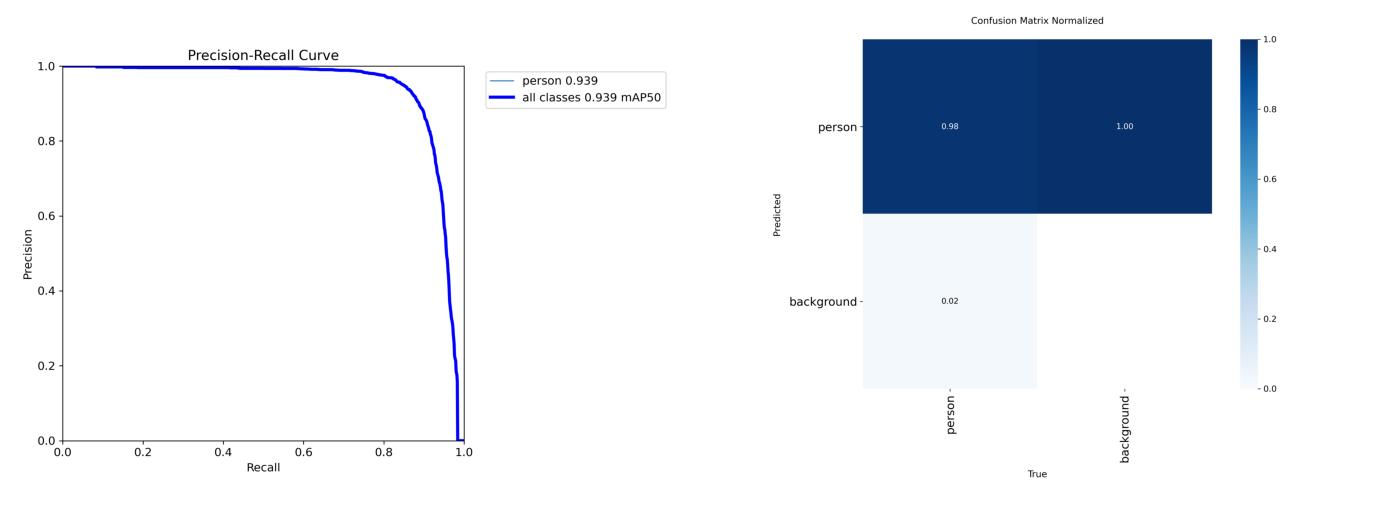

In [24]:
def summary(box):
    per_class = {CLASSES[c]: dict(ap50=float(box.ap50[i]), ap50_95=float(box.ap[i]), precision=float(box.p[i]),
                                  recall=float(box.r[i])) for i, c in enumerate(box.ap_class_index)}
    return dict(map50=float(box.map50), map50_95=float(box.map), precision=float(box.mp), recall=float(box.mr),
                per_class=per_class)


val_runs = {split: val_metrics(best, split, f'val_{split}') for split in ('val', 'test')}
for split, r in val_runs.items():
    print(split, {k: round(v, 4) for k, v in summary(r.box).items() if k != 'per_class'})

FINAL = dict(split=FINAL_SPLIT, **summary(val_runs[FINAL_SPLIT].box))
FINAL['map50_own'], _ = evaluate_map50(predict_records(best, records[FINAL_SPLIT]), records[FINAL_SPLIT], len(CLASSES))
print(f'mAP50 на {FINAL_SPLIT}: ultralytics {FINAL["map50"]:.4f}, evaluate_map50 {FINAL["map50_own"]:.4f}')

save_dir = Path(val_runs[FINAL_SPLIT].save_dir)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ['BoxPR_curve.png', 'confusion_matrix_normalized.png']):
    ax.imshow(plt.imread(save_dir / name))
    ax.set_axis_off()
plt.tight_layout()
plt.show()

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'split': 'test',
 'map50': 0.9393,
 'map50_95': 0.6782,
 'precision': 0.9329,
 'recall': 0.8671,
 'map50_own': 0.9408}

**Ответ:** Класс один, сравнивать классы между собой не с чем. На test mAP50 0.939, mAP50-95 0.678, P 0.933, R 0.867; на val mAP50 0.919, mAP50-95 0.658. Хуже всего модель находит мелких людей: на val пропущено 115 из 334 мелких (34%) и 70 из 1514 крупных (5%), подробнее в 5.1.

Confusion matrix ultralytics считает на test при conf 0.001, с которым идет `val`: 98% людей найдены, 2% попали в строку background, это пропуски. В 5.1 при conf 0.25 пропусков 10.2%. Столбец background состоит из ложных боксов на фоне. При одном классе он нормируется сам на себя и всегда дает 1.00, поэтому полезнее смотреть абсолютные числа.

mAP50-95 ниже mAP50: при IoU 0.75-0.95 нужно точно попасть в края бокса, а края тепловых силуэтов размыты и размечены неодинаково (ноги, отдельная голова). Мой mAP50 0.9408 против 0.9393 у ultralytics, расхождение 0.0015. У меня AP считается по всем точкам PR-кривой, у ultralytics по 101 точке. Кроме того, `val` собирает картинки в батчи прямоугольной формы (rect), а `predict` нет.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a, b = np.asarray(a, dtype=np.float64).reshape(-1, 4), np.asarray(b, dtype=np.float64).reshape(-1, 4)
    wh = np.clip(np.minimum(a[:, None, 2:], b[None, :, 2:]) - np.maximum(a[:, None, :2], b[None, :, :2]), 0, None)
    inter = wh[..., 0] * wh[..., 1]
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    gt_labels = np.asarray(gt['labels'])
    found = np.zeros(len(gt_labels), dtype=bool)
    blamed = np.zeros(len(gt_labels), dtype=bool)   # к gt привязана ошибка класса или локализации
    cats = [None] * len(ious)
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same = gt_labels == pred['labels'][i]
        for cat, mask, flags in (('tp', same & ~found & (ious[i] >= iou_hit), found),
                                 ('class', ~same & (ious[i] >= iou_hit), blamed),
                                 ('localization', same & ~found & (ious[i] >= iou_loc) & (ious[i] < iou_hit), blamed)):
            if mask.any():
                flags[np.where(mask, ious[i], -1).argmax()] = True
                cats[i] = cat
                break
        else:
            cats[i] = 'background'
    return cats, np.flatnonzero(~found & ~blamed).tolist()

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


val, conf >= 0.25: предсказаний 2785, людей в разметке 2802
  tp             2450  88.0%
  class             0  0.0%
  localization     88  3.2%
  background      247  8.9%
  missed          286  10.2%
класс один (person), поэтому разбивка по классам совпадает с общей; пропуски по размеру gt: {'small': '115/334', 'medium': '101/954', 'large': '70/1514'}


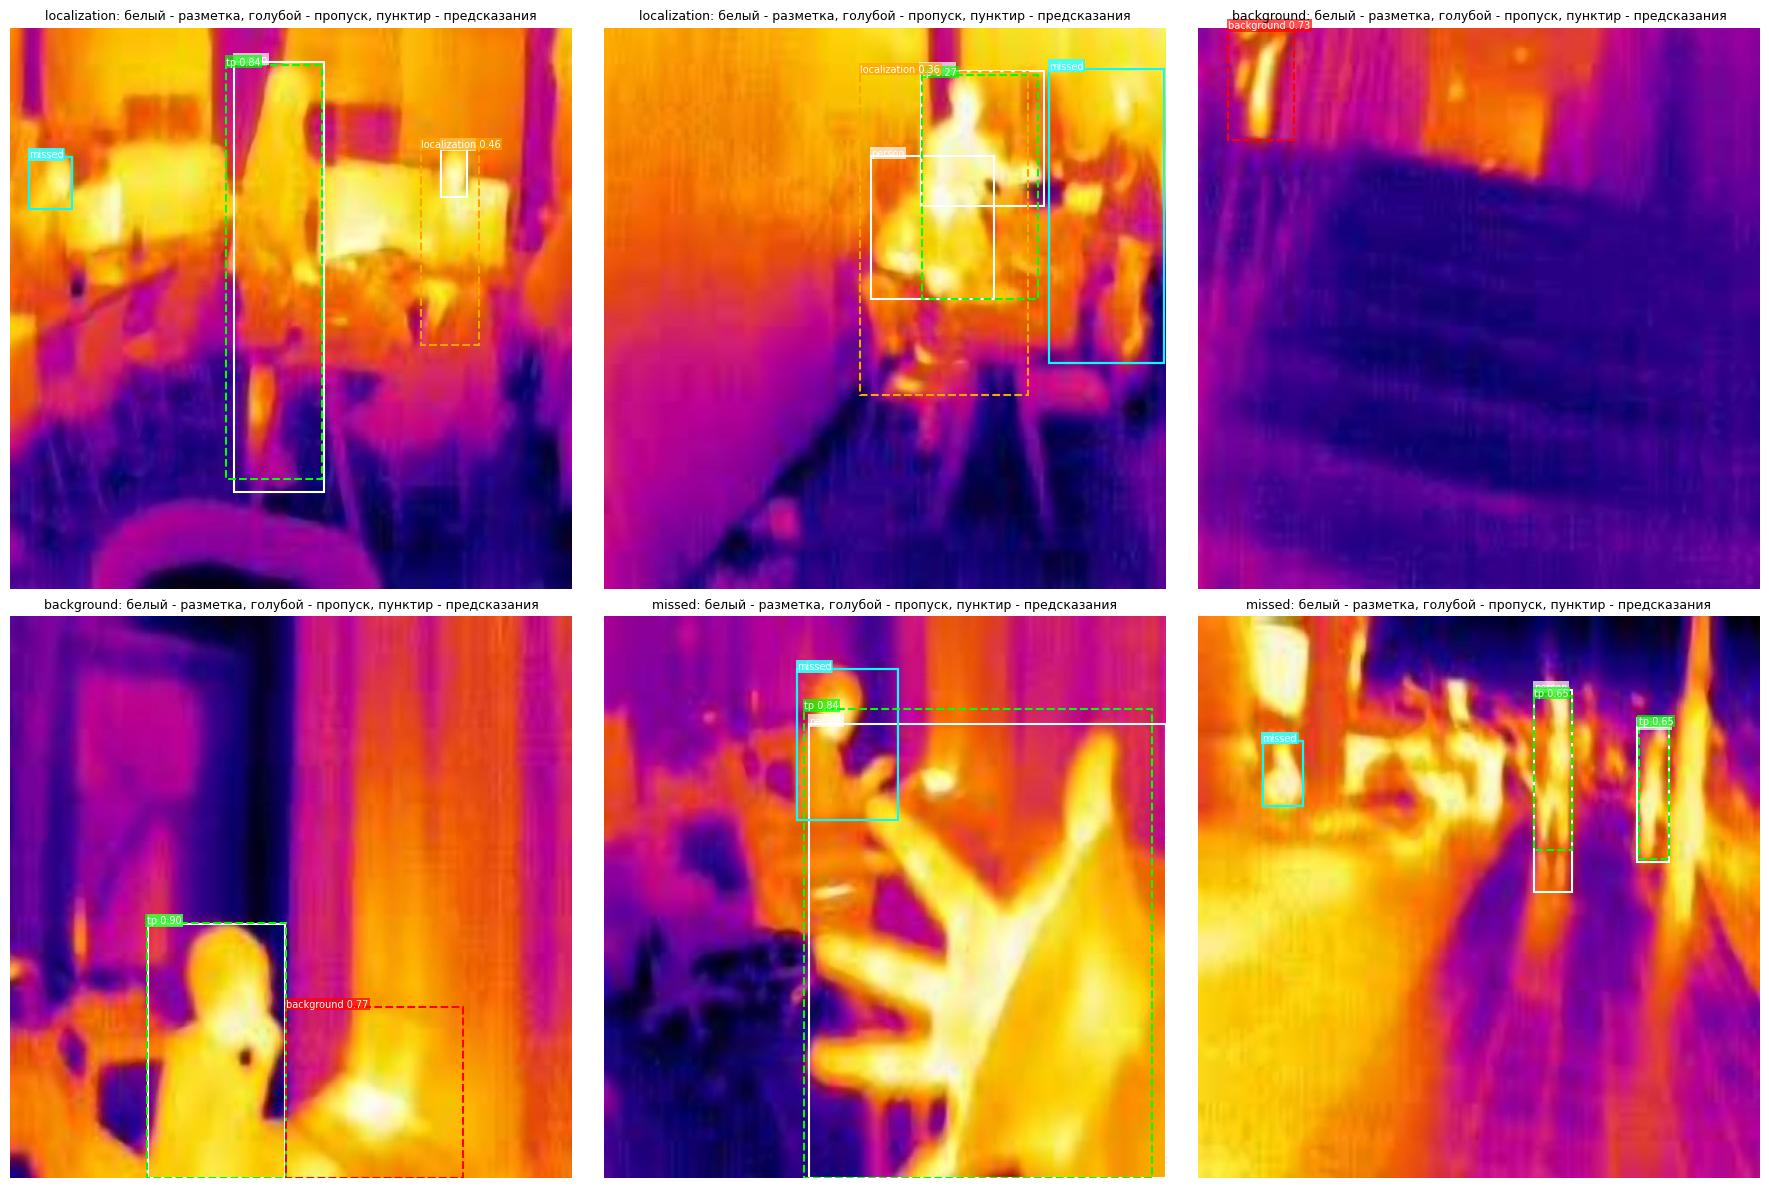

In [28]:
val_preds = predict_records(best, records['val'], conf=CONF_ERRORS)
ERRORS = Counter({t: 0 for t in ERROR_TYPES})
examples = {t: [] for t in ERROR_TYPES}
missed_by_size = Counter()
gt_by_size = Counter()
for k, (p, g) in enumerate(zip(val_preds, records['val'])):
    cats, missed = categorize_predictions(p, g)
    ERRORS.update(cats + ['missed'] * len(missed))
    for t in set(cats + ['missed'] * bool(missed)):
        examples[t].append(k)
    side = np.sqrt(np.prod(g['boxes'][:, 2:] - g['boxes'][:, :2], 1))
    size = np.where(side < 32, 'small', np.where(side < 96, 'medium', 'large'))
    gt_by_size.update(size)
    missed_by_size.update(size[missed])
ERRORS = dict(ERRORS)
n_pred = sum(ERRORS[t] for t in ERROR_TYPES[:4])
n_gt = sum(len(g['labels']) for g in records['val'])
print(f'val, conf >= {CONF_ERRORS}: предсказаний {n_pred}, людей в разметке {n_gt}')
for t in ERROR_TYPES:
    print(f'  {t:<13}{ERRORS[t]:>6}  {ERRORS[t] / (n_gt if t == "missed" else n_pred):.1%}')
print('класс один (person), поэтому разбивка по классам совпадает с общей; пропуски по размеру gt:',
      {s: f'{missed_by_size[s]}/{gt_by_size[s]}' for s in ('small', 'medium', 'large')})

shown = []
for t in ('localization', 'background', 'missed'):
    shown += [(t, k) for k in examples[t] if k not in {kk for _, kk in shown}][:2]
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
colors = {'tp': 'lime', 'localization': 'orange', 'background': 'red', 'class': 'magenta'}
for ax, (t, k) in zip(axes.flat, shown):
    r, p = records['val'][k], val_preds[k]
    cats, missed = categorize_predictions(p, r)
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='white')
    draw_boxes(ax, None, r['boxes'][missed], np.zeros(len(missed)), ['missed'], color='cyan')
    for cat, color in colors.items():
        sel = np.array([c == cat for c in cats], dtype=bool)
        draw_boxes(ax, None, p['boxes'][sel], np.zeros(sel.sum()), [cat], p['scores'][sel], color=color, linestyle='--')
    ax.set_title(f'{t}: белый - разметка, голубой - пропуск, пунктир - предсказания', fontsize=9)
plt.tight_layout()
plt.show()

**Ответ:** На val при conf ≥ 0.25 из 2785 предсказаний 2450 верные (88%), 247 ложных боксов на фоне (8.9%), 88 ошибок локализации (3.2%), ошибок класса нет. Из 2802 людей пропущено 286 (10.2%). Главные категории две, пропуски и фон, и они почти равны.

Пропуски сильно зависят от размера: 34% мелких людей, 11% средних и 5% крупных. Значит, это в основном ошибка модели. На примерах заметная часть ошибок все же идет от разметки. Голову размечают отдельным боксом внутри бокса человека, и он становится пропуском. Человек у края кадра без разметки становится «фоном». Бокс только верхней половины тела засчитывается как ошибка локализации.

Для мелких людей я бы поднял `imgsz` до 960 или резал кадр на тайлы. Для фона и локализации сначала почистил бы разметку от вложенных боксов и дописал пропущенных людей.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
# imgsz 320 против 640: людей меньше 32 px около 10%, при уменьшении картинки вдвое они станут совсем мелкими
small_imgsz = IMGSZ // 2
_, RUN_TIMES['ablation'], abl_dir = train_yolo('ablation_imgsz', **{**TRAIN_ARGS, 'imgsz': small_imgsz})
abl_best = YOLO(abl_dir / 'weights' / 'best.pt')
abl_val = abl_best.val(data=str(DATA_YAML), split='val', imgsz=small_imgsz, batch=BATCH, device=DEVICE, workers=WORKERS,
                       project=str(RUNS.resolve()), name='val_ablation', exist_ok=True, verbose=False)
ABLATION = dict(param='imgsz', values=[IMGSZ, small_imgsz],
                val_map50=[val_runs['val'].box.map50, abl_val.box.map50],
                val_map50_95=[val_runs['val'].box.map, abl_val.box.map],
                val_recall=[val_runs['val'].box.mr, abl_val.box.mr],
                train_time_sec=[RUN_TIMES['train'], RUN_TIMES['ablation']],
                latency_ms=[measure_latency(best, IMGSZ), measure_latency(abl_best, small_imgsz)])
for i, v in enumerate(ABLATION['values']):
    print(f'imgsz {v}: ' + ', '.join(f'{k} {ABLATION[k][i]:.3f}' for k in ABLATION if k not in ('param', 'values')))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ablation_imgsz, nbs=64, nms=None, opset=None, optimize=False, optimizer

**Ответ:** Сравнивал `imgsz` 320 и 640. С 320 mAP50 на val упал с 0.919 до 0.895, mAP50-95 с 0.658 до 0.622, recall с 0.833 до 0.806. Обучение ускорилось в 2.3 раза (787 с против 1827 с), задержка снизилась с 15.0 до 9.9 мс. Потеря понятна: при 320 мелкие люди (11.9% боксов) становятся меньше 16 px, а точность краев бьет по mAP50-95 сильнее, чем по mAP50.

Для финальной модели 640 стоит своих денег: обучение длится полчаса, а 3.6 пункта mAP50-95 заметны. На слабом устройстве, где важны миллисекунды, я бы взял 320 и смирился с потерей 2.4 пункта mAP50.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** Дообучение `yolo26s` на 3000 тепловизионных кадрах подняло mAP50 на test с 0.532 у COCO-модели до 0.939, mAP50-95 до 0.678; эвристика без нейросети дает 0.032. Разбиение по группам убрало утечку: в исходных сплитах кадры одних и тех же видео попадали и в train, и в test. Сработали и аугментации без сдвига тона. Главные остаточные ошибки: пропуски мелких людей (34% мелких против 5% крупных) и ложные боксы на теплом фоне, причем часть ошибок объясняется разметкой (вложенные боксы, неразмеченные люди). RT-DETR-l не обогнал YOLO: mAP50-95 на test 0.674 против 0.678 при задержке в 4.5 раза больше. TensorRT FP16 ускорил инференс в 2.75 раза без потери mAP. Модель чувствительна к шуму: при σ=25 mAP50 падает до 0.500.

Ограничения: один seed, половина train (3000 из 6144 картинок), val и test по 1317 картинок, и все цифры на одном датасете с одним типом камер. Дальше я бы обучил на полном train, добавил шумовые и JPEG-аугментации, попробовал `imgsz` 960 для мелких людей и почистил разметку.

Отдельно интересно было бы посмотреть, какие признаки YOLO выделяет на тепловизионных кадрах. По моему опыту, тепловизор примерно раз в 15 секунд перекалибровывается, чтобы держать качество картинки. Если backbone опирается на признаки, связанные с температурой фона, после такой перекалибровки могут начаться проблемы. Этот датасет в этом смысле несложный: в кадре нет очень горячих объектов, которые сильно меняют цвет всего фона и человека. Так что модель, возможно, переобучена под условия съемки именно этого датасета.

В реальной задаче я бы сначала отдельно дообучил backbone и посмотрел, какие признаки он выделяет. Лучше всего было бы дистиллировать из сильной модели, но свежих моделей, обученных на тепловизионных данных, мало. Поэтому в последнее время я обучаю backbone self-supervised по схеме JEPA с SIGReg и смотрю, какие признаки он выделяет после разного числа эпох. Это затратно по вычислениям, поэтому в рамках лабы я этим не занимался. Еще можно было бы усреднять веса нескольких чекпоинтов (model soup), чтобы поднять метрику, но это тоже выходит за рамки лабы и требует больше вычислений.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** 

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR

    rtdetr = RTDETR('rtdetr-l.pt')
    rtdetr_params = count_params(rtdetr.model)
    start = time.perf_counter()
    rtdetr.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name='rtdetr',
                 exist_ok=True, verbose=False, **{**TRAIN_ARGS, 'lr0': 1e-4})   # трансформеру с AdamW нужен lr на порядок ниже
    RUN_TIMES['rtdetr'] = time.perf_counter() - start
    rtdetr_best = RTDETR(Path(rtdetr.trainer.save_dir) / 'weights' / 'best.pt')

    compare = {}
    for name, model, params, sec in (('yolo26s', best, sum(blocks.values()), RUN_TIMES['train']),
                                     ('rtdetr-l', rtdetr_best, rtdetr_params, RUN_TIMES['rtdetr'])):
        row = dict(params=params, train_min=round(sec / 60, 1), latency_ms=round(measure_latency(model), 2))
        for split in ('val', 'test'):
            r = model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                          project=str(RUNS.resolve()), name=f'val_{name}_{split}', exist_ok=True, verbose=False)
            row[f'{split} mAP50'], row[f'{split} mAP50-95'] = round(r.box.map50, 4), round(r.box.map, 4)
        compare[name] = row
        print(name, row)
    (artifact_dir / 'bonus_6_2.json').write_text(json.dumps(json_ready(compare), indent=2))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/30        13G       1.02     0.8165     0.5229         29        640: 100% ━━━━━━━━━━━━ 188/188 1.0s/it 3:16
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 1.4it/s 29.9s
                   all       1317       2802      0.154      0.341       0.12     0.0427

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/30      12.9G     0.6063     0.9527     0.2564         22        640: 100% ━━━━━━━━━━━━ 188/188 1.0s/it 3:09
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 1.5it/s 28.0s
                   all       1317       2802      0.132      0.435      0.128     0.0629

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (51 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      29/30      12.9G     0.2802     0.3623     0.1358         23        640: 100% ━━━━━━━━━━━━ 188/188 1.0s/it 3:09
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 1.5it/s 28.2s
                   all       1317       2802      0.908      0.859      0.917       0.66

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      30/30      12.9G     0.2795      0.361     0.1354         13        640: 100% ━━━━━━━━━━━━ 188/188 1.0s/it 3:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 1.5it/s 28.1s
                   all       1317       2802       0.91       0.86      0.917       0.66

30 epochs completed in 1.836 hours.
Optimizer stripped from /kaggle/working/runs_hw2/rtdetr/weights/last.pt, 66.2MB
Optimizer stripped from /kaggle/working/runs_hw2/rtdetr/weights/best.pt, 66.2MB

Validating /kaggle/working/runs_hw2/rtdetr/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 1.5it/s 27.2s
                   all       1317       2802       0.91       0.86      0.917      0.659
Speed: 0.2ms pre

**Ответ:** RT-DETR-l обучался на тех же данных и эпохах с lr0 1e-4. На test он дал mAP50 0.927 против 0.939 у YOLO и mAP50-95 0.674 против 0.678, на val mAP50-95 почти поровну (0.660 против 0.658). При этом у него в 3.3 раза больше параметров (33.0 млн против 10.0 млн), обучение в 3.6 раза дольше (111 мин против 31) и задержка в 4.5 раза больше (68.1 мс против 15.2).

На этой задаче RT-DETR ничего не выиграл, при одном seed разница в качестве в пределах шума. Я бы выбрал его для плотных сцен с перекрытиями, где глобальный attention помогает разделять объекты, и когда есть запас по GPU и времени на длинное обучение.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1138.7±225.2 MB/s, size: 42.9 KB)
val: Scanning /kaggle/working/data/yolo/labels/val_dark... 1317 images, 114 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1317/1317 1.3Kit/s 1.0s
val: New cache created: /kaggle/working/data/yolo/labels/val_dark.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 83/83 3.5it/s 23.5s
                   all       1317       2802      0.889      0.801      0.883      0.618
Speed: 0.9ms preprocess, 13.6ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/runs_hw2/val_shift_dark
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast

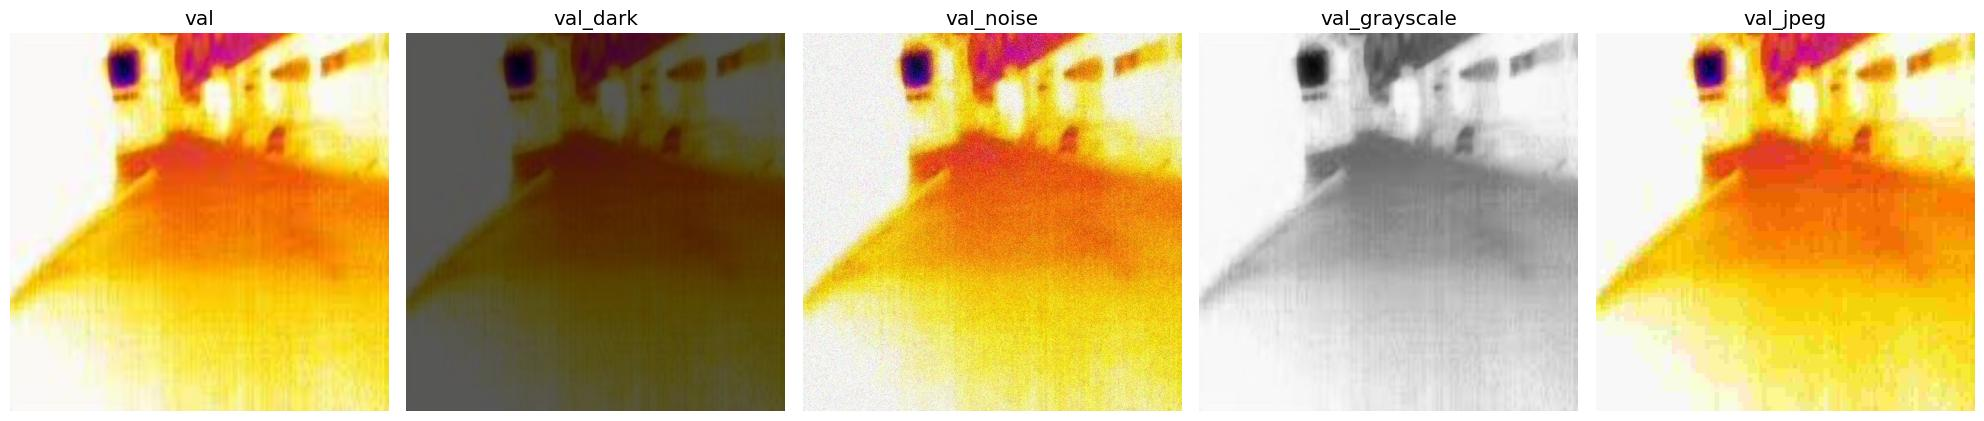

In [33]:
if '6.3' in BONUS_TASKS:
    rng = np.random.default_rng(SEED)
    shifts = {
        'dark': lambda a: a * 0.35,
        'noise': lambda a: a + rng.normal(0, 25, a.shape),
        'grayscale': lambda a: np.repeat((a @ [0.299, 0.587, 0.114])[..., None], 3, axis=2),   # white-hot вместо цветной палитры
    }
    shift_yaml = DATA_YAML.read_text()
    for kind in [*shifts, 'jpeg']:
        img_dir = YOLO_ROOT / 'images' / f'val_{kind}'
        img_dir.mkdir(exist_ok=True)
        shutil.copytree(YOLO_ROOT / 'labels' / 'val', YOLO_ROOT / 'labels' / f'val_{kind}', dirs_exist_ok=True)
        for src in sorted((YOLO_ROOT / 'images' / 'val').glob('*.jpg')):
            a = np.asarray(Image.open(src).convert('RGB'), dtype=np.float64)
            out = a if kind == 'jpeg' else shifts[kind](a)
            Image.fromarray(np.clip(out, 0, 255).astype(np.uint8)).save(img_dir / src.name, quality=10 if kind == 'jpeg' else 95)
        shift_yaml += f'val_{kind}: {img_dir.resolve().as_posix()}\n'   # нестандартные сплиты ultralytics не склеивает с path
    (YOLO_ROOT / 'shift.yaml').write_text(shift_yaml)

    shift_results = {'clean': dict(map50=val_runs['val'].box.map50, map50_95=val_runs['val'].box.map, recall=val_runs['val'].box.mr)}
    for kind in [*shifts, 'jpeg']:
        r = best.val(data=str(YOLO_ROOT / 'shift.yaml'), split=f'val_{kind}', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                     workers=WORKERS, project=str(RUNS.resolve()), name=f'val_shift_{kind}', exist_ok=True, verbose=False)
        shift_results[kind] = dict(map50=r.box.map50, map50_95=r.box.map, recall=r.box.mr)
    for kind, row in shift_results.items():
        print(f'{kind:<10}' + ', '.join(f'{k} {v:.3f}' for k, v in row.items()))

    example = sorted((YOLO_ROOT / 'images' / 'val').glob('*.jpg'))[3].name
    fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
    for ax, kind in zip(axes, ['val'] + [f'val_{k}' for k in [*shifts, 'jpeg']]):
        ax.imshow(Image.open(YOLO_ROOT / 'images' / kind / example))
        ax.set_title(kind)
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()
    (artifact_dir / 'bonus_6_3.json').write_text(json.dumps(json_ready(shift_results), indent=2))

**Ответ:** Сильнее всего бьет гауссов шум σ=25: mAP50 на val падает с 0.919 до 0.500, recall с 0.833 до 0.430. Дальше идут JPEG с качеством 10 (0.822), затемнение ×0.35 (0.883) и перевод в оттенки серого (0.905). Класс один, так что разбивки по классам нет. Шум и блоки JPEG разрушают как раз мелкие размытые силуэты, на которых модель и так ошибается.

Серый почти не мешает: в датасете уже есть кадры в оттенках серого, и модель опирается на яркость, а не на тон. Помогли бы аугментации шумом и сжатием (GaussNoise и ImageCompression из Albumentations); у тепловизоров собственный шум матрицы, так что такой сдвиг реалистичен.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if '6.4' in BONUS_TASKS:
    # TensorRT 11 в ultralytics требует nvidia-modelopt, который тянет свою версию torch; TensorRT 10 обходится без него
    if importlib.util.find_spec('tensorrt') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tensorrt-cu12>=10.15,<11', 'onnx', 'onnxruntime-gpu'],
                       check=True)
    best_pt = run_dir / 'weights' / 'best.pt'
    onnx_file = Path(YOLO(best_pt).export(format='onnx', imgsz=IMGSZ, batch=1, device=DEVICE))
    onnx_file = shutil.copy(onnx_file, onnx_file.with_name('best_fp32.onnx'))   # экспорт в TensorRT перезапишет best.onnx
    variants = {'pytorch fp32': (best_pt, {}), 'pytorch fp16': (best_pt, {'quantize': 16}), 'onnx fp32': (onnx_file, {})}
    for bits, name in ((16, 'fp16'), (8, 'int8')):
        # INT8 калибруется на train: в calib.yaml сплит val указывает на картинки train
        (YOLO_ROOT / 'calib.yaml').write_text(DATA_YAML.read_text().replace('val: images/val', 'val: images/train'))
        engine = YOLO(best_pt).export(format='engine', imgsz=IMGSZ, batch=1, device=DEVICE, quantize=bits,
                                      data=str(YOLO_ROOT / 'calib.yaml'))
        variants[f'tensorrt {name}'] = (Path(engine).rename(Path(engine).with_name(f'best_{name}.engine')), {})

    speed = {}
    for name, (path, kw) in variants.items():
        model = YOLO(path, task='detect')
        # rect=False у всех: у ONNX и TensorRT ultralytics его выключает сам, и это меняет mAP сильнее, чем экспорт
        r = model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1, device=DEVICE, workers=WORKERS, rect=False,
                      project=str(RUNS.resolve()), name=f'val_{name.replace(" ", "_")}', exist_ok=True, verbose=False, **kw)
        speed[name] = dict(mb=round(Path(path).stat().st_size / 2**20, 1), latency_ms=round(measure_latency(model, **kw), 2),
                           map50=round(r.box.map50, 4), map50_95=round(r.box.map, 4))
    print(f'{DEVICE_NAME}, batch 1, imgsz {IMGSZ}')
    for name, row in speed.items():
        print(f'{name:<14}', row, f'ускорение x{speed["pytorch fp32"]["latency_ms"] / row["latency_ms"]:.2f}')
    (artifact_dir / 'bonus_6_4.json').write_text(json.dumps(json_ready(speed), indent=2))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs

PyTorch: starting from '/kaggle/working/runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (19.4 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 614ms
Prepared 1 package in 149ms
Installed 1 package in 7ms
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.7s, saved as '/kaggle/working/runs_hw2/finetune/

**Ответ:** Мерил на Tesla T4, batch 1, 640, после прогрева, все варианты валидировались одинаково с `rect=False`. TensorRT FP16 дает 5.67 мс против 15.58 мс у PyTorch FP32, ускорение в 2.75 раза, при этом mAP50 0.9178 против 0.9180. TensorRT INT8 с калибровкой на train дает 5.43 мс (×2.87) и файл 13.0 МБ вместо 19.4, но mAP50 падает до 0.9069 и mAP50-95 с 0.657 до 0.640. ONNX в onnxruntime не ускорил (16.5 мс), PyTorch FP16 дал ×1.25.

Ускорение дают слияние слоев, подобранные под T4 ядра и тензорные ядра в FP16. INT8 почти не быстрее FP16: у модели на 10 млн параметров при batch 1 время уходит на запуск ядер, пред- и постобработку, а не на сами свертки. Для этой модели я бы выбрал FP16.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 864.3±634.7 MB/s, size: 35.1 KB)
val: Scanning /kaggle/working/data/yolo/labels/val.cache... 1317 images, 114 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1317/1317 230.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 83/83 3.9it/s 21.5s
                   all       1317       2802      0.902      0.855      0.923      0.649
Speed: 0.8ms preprocess, 13.1ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 937.8±574.1 MB/s, size: 36.4 KB)
val: Scanning /kaggle/working/data/yolo/labels/val.ca

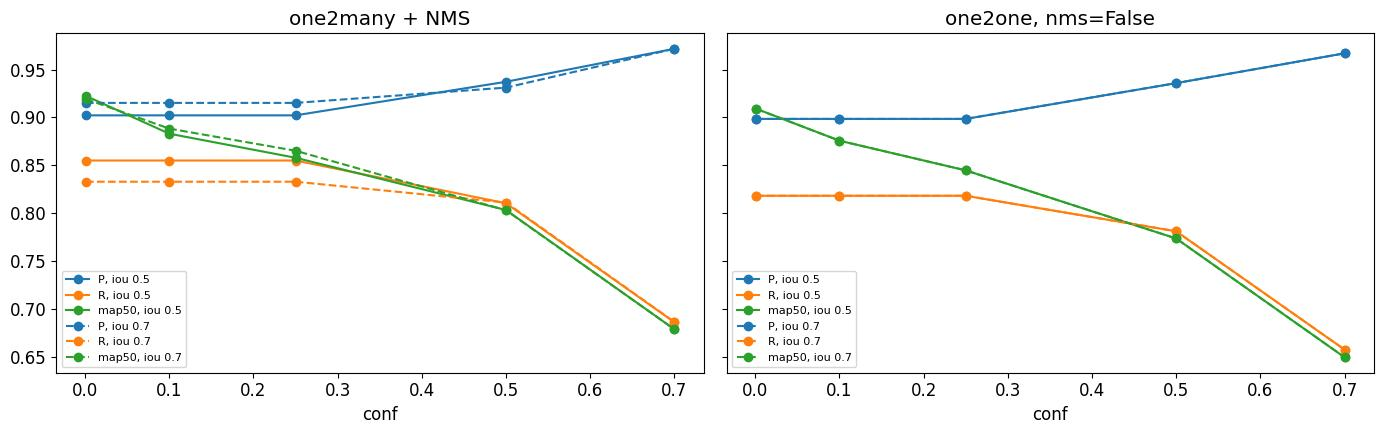

In [35]:
if '6.5' in BONUS_TASKS:
    thresholds = []
    for nms in (None, False):   # None: one2many + NMS (по умолчанию в этой версии), False: one2one без NMS
        for conf in (0.001, 0.1, 0.25, 0.5, 0.7):
            for iou in (0.5, 0.7):
                r = best.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                             conf=conf, iou=iou, nms=nms, plots=False, project=str(RUNS.resolve()), name='val_thresholds',
                             exist_ok=True, verbose=False)
                thresholds.append(dict(nms=nms, conf=conf, iou=iou, P=r.box.mp, R=r.box.mr, map50=r.box.map50, map50_95=r.box.map))
    for row in thresholds:
        print(', '.join(f'{k} {v:.3f}' if isinstance(v, float) else f'{k} {v}' for k, v in row.items()))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, nms in zip(axes, (None, False)):
        for iou, ls in ((0.5, '-'), (0.7, '--')):
            rows = [r for r in thresholds if r['nms'] is nms and r['iou'] == iou]
            for key, color in (('P', 'C0'), ('R', 'C1'), ('map50', 'C2')):
                ax.plot([r['conf'] for r in rows], [r[key] for r in rows], ls, color=color, marker='o', label=f'{key}, iou {iou}')
        ax.set(title='one2many + NMS' if nms is None else 'one2one, nms=False', xlabel='conf')
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    (artifact_dir / 'bonus_6_5.json').write_text(json.dumps(json_ready(thresholds), indent=2))

**Ответ:** Для поиска людей на тепловизоре пропуск дороже ложной тревоги, поэтому я бы взял conf 0.25 с NMS (`iou=0.7` по умолчанию): на val P 0.915, R 0.833. При conf 0.5 recall падает до 0.81, при 0.7 до 0.69. P и R ultralytics печатает в точке максимального F1. Пока conf ниже этой точки, они не меняются, а когда выше, отрезанные боксы сдвигают их сильно.

mAP интегрирует PR-кривую по всем порогам, поэтому при малом conf почти не меняется (0.919 при conf 0.001 и 0.888 при 0.1). При большом conf кривая обрезается справа, и mAP50 падает до 0.679 при 0.7.

`iou` влияет только с NMS: при conf 0.001 mAP50 0.923 с `iou=0.5` и 0.919 с `iou=0.7`. В end-to-end режиме (`nms=False`, ветка one2one) строки с `iou` 0.5 и 0.7 совпадают до последнего знака, и mAP50 там 0.909, чуть ниже, чем с NMS.